In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

### . Regression Modeling (Sale Price Prediction) ---

In [2]:
X_train_reg = pd.read_csv("newdata/X_train_df.csv")
X_test_reg = pd.read_csv("newdata/X_test_df.csv")

In [3]:
y_train_reg = pd.read_csv("y_train_reg.csv")
y_test_reg = pd.read_csv("y_test_reg.csv")

In [4]:
print((X_train_reg.shape, y_train_reg.shape))

((800000, 20), (800000, 1))


In [5]:
print((X_test_reg.shape, y_test_reg.shape))

((200000, 20), (200000, 1))


In [7]:
X_train_reg.head()

,Lot_Size_Acres,Transit_Score,Crime_Index,School_District_Rating,Environmental_Risk_Score,Energy_Efficiency_Rating,Property_Age,Transit_to_Distance_Ratio,Property_Type_Commercial,Property_Type_Condo,Property_Type_Multi-Family,Property_Type_Single Family,Zoning_Code_COMM,Zoning_Code_RES-A,Zoning_Code_RES-B,Country_Code_DE,Country_Code_IN,Country_Code_UK,Country_Code_US,SqFt_Age
0,-0.691411,-0.063736,-0.788481,5,0.604643,0.0,0.978674,-0.523660,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,-1.149215
1,-1.569816,0.240586,0.386434,1,1.367528,5.0,1.610624,-0.449545,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,2.613689
2,-0.326077,-0.983808,-0.291402,5,0.882056,0.0,-1.416085,-0.623923,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,-1.002640
3,1.610348,-0.867098,1.019080,8,0.361907,3.0,-1.283043,-0.621790,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.905441
4,-0.173449,0.962818,-0.924048,9,-0.678390,3.0,1.377800,0.619132,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,-0.568936


In [8]:
y_train_reg.head()

,Sale_Price
0,9.001201e+05
1,4.184753e+06
2,2.720607e+06
3,5.149486e+05
4,1.894646e+06


### 3. Train a baseline Linear Regression model on the data.

In [9]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [10]:
lr = LinearRegression()

In [11]:
lr.fit(X_train_reg, y_train_reg)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 20)","[[ 358.99, 17626.3 ,-12575.17,..., 6272.22, 1706.96, -774.18]]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](20,)","['Lot_Size_Acres','Transit_Score','Crime_Index',...,'Country_Code_UK', 'Country_Code_US','SqFt_Age']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[1855176.21]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,20
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,19


In [13]:
y_pred_lr = lr.predict(X_test_reg)

### Calculate the Root Mean Squared Error (RMSE) and R-Squared (R2) on the test set.

In [14]:
# Evaluation
mae = mean_absolute_error(y_test_reg, y_pred_lr)
mse = mean_squared_error(y_test_reg, y_pred_lr)
rmse = np.sqrt(mse)
r2 = r2_score(y_test_reg, y_pred_lr)

In [15]:
print("Baseline Linear Regression")
print("-" * 35)
print(f"MAE  : {mae:.4f}")
print(f"MSE  : {mse:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"R²   : {r2:.4f}")

Baseline Linear Regression
-----------------------------------
MAE  : 997743.6493
MSE  : 1390953267455.9348
RMSE : 1179386.8184
R²   : 0.0963


In [23]:
print("y_train:")
print(y_train_reg.describe())

print("\ny_test:")
print(y_test_reg.describe())

print("\nPredictions:")
print(pd.Series(y_pred_lr.squeeze()).describe())

y_train:
         Sale_Price
count  8.000000e+05
mean   2.235945e+06
std    1.239832e+06
min    5.000000e+04
25%    1.210903e+06
50%    2.168606e+06
75%    3.123839e+06
max    7.337107e+06

y_test:
         Sale_Price
count  2.000000e+05
mean   2.240068e+06
std    1.240628e+06
min    5.000000e+04
25%    1.214189e+06
50%    2.173617e+06
75%    3.133290e+06
max    7.235753e+06

Predictions:
count    2.000000e+05
mean     2.236386e+06
std      3.850450e+05
min      1.814473e+06
25%      2.019543e+06
50%      2.105544e+06
75%      2.204303e+06
max      3.372445e+06
dtype: float64


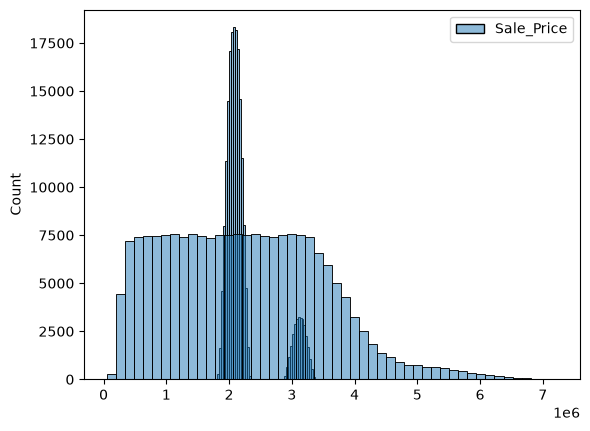

In [17]:
# plotting the graph of prediction and actual values.
sns.histplot( y_pred_lr, color= 'red', alpha = 0.5, bins= 50)
sns.histplot( y_test_reg, color = 'blue', alpha =0.5, bins= 50)
plt.show()

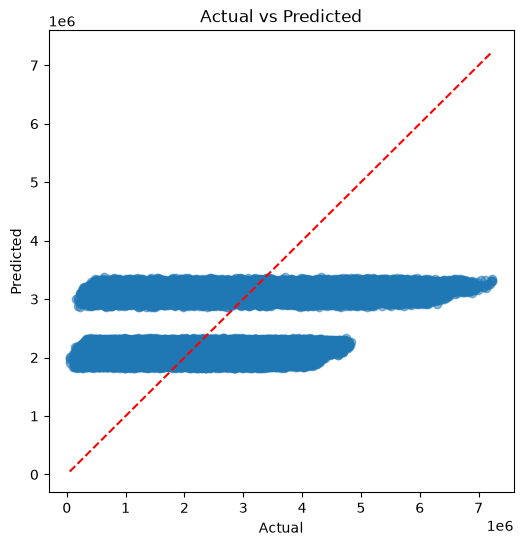

In [20]:
plt.figure(figsize=(6,6))
plt.scatter(y_test_reg, y_pred_lr, alpha=0.5)
plt.plot(
    [y_test_reg.min(), y_test_reg.max()],
    [y_test_reg.min(), y_test_reg.max()],
    "r--"
)
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Actual vs Predicted")
plt.show()

In [26]:
X_train_reg.isna().sum()

Lot_Size_Acres                 0
Transit_Score                  0
Crime_Index                    0
School_District_Rating         0
Environmental_Risk_Score       0
Energy_Efficiency_Rating       0
Property_Age                   0
Transit_to_Distance_Ratio      0
Property_Type_Commercial       0
Property_Type_Condo            0
Property_Type_Multi-Family     0
Property_Type_Single Family    0
Zoning_Code_COMM               0
Zoning_Code_RES-A              0
Zoning_Code_RES-B              0
Country_Code_DE                0
Country_Code_IN                0
Country_Code_UK                0
Country_Code_US                0
SqFt_Age                       0
dtype: int64

- Multicoliniarity between Zoning_cde_COMM and Property_Type_Commercial
- So I would check, confirm and drop one of them.
- Again train model of LR and see results.

In [27]:
print((X_train_reg["Zoning_Code_COMM"] == X_train_reg["Property_Type_Commercial"]).all())

True


In [28]:
print(pd.crosstab(X_train_reg["Zoning_Code_COMM"],X_train_reg["Property_Type_Commercial"]))

Property_Type_Commercial     0.0     1.0
Zoning_Code_COMM                        
0.0                       679443       0
1.0                            0  120557


In [29]:
X_train_reg = X_train_reg.drop(columns=["Zoning_Code_COMM"])
X_test_reg = X_test_reg.drop(columns=["Zoning_Code_COMM"])

In [31]:
### New Linear Regression model

In [32]:
lr_model = LinearRegression()

In [33]:
lr_model.fit(X_train_reg, y_train_reg)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 19)","[[ 358.99, 17626.3 ,-12575.17,..., 6272.22, 1706.96, -774.18]]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](19,)","['Lot_Size_Acres','Transit_Score','Crime_Index',...,'Country_Code_UK', 'Country_Code_US','SqFt_Age']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[1855176.21]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,19
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,19


In [34]:
y_pred = lr_model.predict(X_test_reg)

In [38]:
# Evaluation
mae2 = mean_absolute_error(y_test_reg, y_pred)
mse2 = mean_squared_error(y_test_reg, y_pred)
rmse2 = np.sqrt(mse)
r2 = r2_score(y_test_reg, y_pred)

In [39]:
print("Baseline Linear Regression")
print("-" * 35)
print(f"MAE  : {mae2:.4f}")
print(f"MSE  : {mse2:.4f}")
print(f"RMSE : {rmse2:.4f}")
print(f"R²   : {r2:.4f}")

Baseline Linear Regression
-----------------------------------
MAE  : 997743.6493
MSE  : 1390953267455.9348
RMSE : 1179386.8184
R²   : 0.0963


- Finding not much difference after droping one column.
- Lets see some the EDA to find culprit.
- But find almost everything okay.

print("X_train shape:", X_train_reg.shape)
print("X_test shape :", X_test_reg.shape)

print("Number of features:", X_train_reg.shape[1])

In [41]:
print(X_train_reg.dtypes.value_counts())

float64    18
int64       1
Name: count, dtype: int64


In [42]:
print(X_train_reg.std().sort_values().head(20))

Property_Type_Multi-Family     0.218435
Country_Code_DE                0.356335
Country_Code_IN                0.357512
Property_Type_Commercial       0.357753
Country_Code_UK                0.400566
Property_Type_Condo            0.433207
Zoning_Code_RES-A              0.450259
Zoning_Code_RES-B              0.450519
Property_Type_Single Family    0.489766
Country_Code_US                0.489865
Transit_Score                  1.000001
Property_Age                   1.000001
Lot_Size_Acres                 1.000001
Environmental_Risk_Score       1.000001
Transit_to_Distance_Ratio      1.000001
Crime_Index                    1.000001
SqFt_Age                       1.000687
Energy_Efficiency_Rating       1.707744
School_District_Rating         2.873375
dtype: float64


In [43]:
print(X_train_reg.describe().T)

                                count          mean       std       min  \
Lot_Size_Acres               800000.0  3.717050e-12  1.000001 -1.732316   
Transit_Score                800000.0  3.695518e-10  1.000001 -2.026462   
Crime_Index                  800000.0  3.704800e-10  1.000001 -1.782639   
School_District_Rating       800000.0  5.494909e+00  2.873375  1.000000   
Environmental_Risk_Score     800000.0  2.405089e-09  1.000001 -1.718687   
Energy_Efficiency_Rating     800000.0  2.499757e+00  1.707744  0.000000   
Property_Age                 800000.0  1.044113e-10  1.000001 -1.715430   
Transit_to_Distance_Ratio    800000.0 -3.365970e-09  1.000001 -0.685220   
Property_Type_Commercial     800000.0  1.506963e-01  0.357753  0.000000   
Property_Type_Condo          800000.0  2.503362e-01  0.433207  0.000000   
Property_Type_Multi-Family   800000.0  5.023750e-02  0.218435  0.000000   
Property_Type_Single Family  800000.0  3.993563e-01  0.489766  0.000000   
Zoning_Code_RES-A        

### Train a Ridge Regression model (alpha=1.0) to handle any remaining multicollinearity. Evaluate RMSE/R2

In [45]:
from sklearn.linear_model import Ridge

In [46]:
ridge_model = Ridge(alpha=1.0)

In [47]:
ridge_model.fit(X_train_reg, y_train_reg)

,"alpha alpha: float or array-like of shape (n_targets,), default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.See :ref:`sphx_glr_auto_examples_linear_model_plot_ridge_coeffs.py`for an illustration of the effect of alpha on the model coefficients.",1.0
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None
,"tol tol: float, default=1e-4The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for each solver:- 'svd': `tol` has no impact.- 'cholesky': `tol` has no impact.- 'sparse_cg': norm of residuals smaller than `tol`.- 'lsqr': `tol` is set as atol and btol of scipy.sparse.linalg.lsqr, which control the norm of the residual vector in terms of the norms of matrix and coefficients.- 'sag' and 'saga': relative change of coef smaller than `tol`.- 'lbfgs': maximum of the absolute (projected) gradient=max|residuals| smaller than `tol`... versionchanged:: 1.2 Default value changed from 1e-3 to 1e-4 for consistency with other linear models.",0.0001
,"solver solver: {'auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga', 'lbfgs'}, default='auto'Solver to use in the computational routines:- 'auto' chooses the solver automatically based on the type of data.- 'svd' uses a Singular Value Decomposition of X to compute the Ridge coefficients. It is the most stable solver, in particular more stable for singular matrices than 'cholesky' at the cost of being slower.- 'cholesky' uses the standard :func:`scipy.linalg.solve` function to obtain a closed-form solution.- 'sparse_cg' uses the conjugate gradient solver as found in :func:`scipy.sparse.linalg.cg`. As an iterative algorithm, this solver is more appropriate than 'cholesky' for large-scale data (possibility to set `tol` and `max_iter`).- 'lsqr' uses the dedicated regularized least-squares routine :func:`scipy.sparse.linalg.lsqr`. It is the fastest and uses an iterative procedure.- 'sag' uses a Stochastic Average Gradient descent, and 'saga' uses its improved, unbiased version named SAGA. Both methods also use an iterative procedure, and are often faster than other solvers when both n_samples and n_features are large. Note that 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`.- 'lbfgs' uses L-BFGS-B algorithm implemented in :func:`scipy.optimize.minimize`. It can be used only when `positive` is True.All solvers except 'svd' support both dense and sparse data. However, only'lsqr', 'sag', 'sparse_cg', and 'lbfgs' support sparse input when`fit_intercept` is True... versionadded:: 0.17 Stochastic Average Gradient descent solver... versionadded:: 0.19 SAGA solver.",'auto'
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.Only 'lbfgs' solver is supported in this case.",False
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag' or 'saga' 

In [48]:
y_pred_ridge = ridge_model.predict(X_test_reg)

In [51]:
# Evaluate
rmse = np.sqrt(mean_squared_error(y_test_reg, y_pred_ridge))
r2 = r2_score(y_test_reg, y_pred_ridge)

In [52]:
print("Ridge Regression (alpha=1.0)")
print(f"RMSE : {rmse:.4f}")
print(f"R²   : {r2:.4f}")

Ridge Regression (alpha=1.0)
RMSE : 1179386.8069
R²   : 0.0963


### Train a Lasso Regression model. Observe if it shrinks any feature coefficients to exactly zero (L1 regularization feature selection).

In [53]:
from sklearn.linear_model import Lasso
lasso_model = Lasso(alpha=1.0, max_iter=10000)

In [54]:
lasso_model.fit(X_train_reg, y_train_reg)

,"max_iter max_iter: int, default=1000The maximum number of iterations.",10000
,"alpha alpha: float, default=1.0Constant that multiplies the L1 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Lasso` object is not advised.Instead, you should use the :class:`LinearRegression` object.",1.0
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"precompute precompute: bool or array-like of shape (n_features, n_features), default=FalseWhether to use a precomputed Gram matrix to speed upcalculations. The Gram matrix can also be passed as argument.For sparse input this option is always ``False`` to preserve sparsity.",False
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``, see Notes below.",0.0001
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fit asinitialization, otherwise, just erase the previous solution.See :term:`the Glossary <warm_start>`.",False
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.",False
,"random_state random_state: int, RandomState instance, default=NoneThe seed of the pseudo random number generator that selects a randomfeature to update. Used when ``selection`` == 'random'.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"selection selection: {'cyclic', 'random'}, default='cyclic'If set to 'random', a random coefficient is updated every iterationrather than looping over features sequentially by default. This(setting to 'random') often leads to significantly faster convergenceespecially when tol is higher than 1e-4.",'cyclic'
Name,Type,Value


In [55]:
y_pred_lasso = lasso_model.predict(X_test_reg)

In [57]:
# Evaluation
rmse_lasso = np.sqrt(mean_squared_error(y_test_reg, y_pred_lasso))
r2_lasso = r2_score(y_test_reg, y_pred_lasso)

print("Lasso Regression")
print(f"RMSE : {rmse_lasso:.4f}")
print(f"R²   : {r2_lasso:.4f}")

Lasso Regression
RMSE : 1179386.7351
R²   : 0.0963


In [58]:
feature_names = X_train_reg.columns
lasso_coefficients = pd.DataFrame({
                          "Feature": feature_names,
                          "Coefficient": lasso_model.coef_})
print(lasso_coefficients)

                        Feature   Coefficient
0                Lot_Size_Acres  3.579474e+02
1                 Transit_Score  1.762568e+04
2                   Crime_Index -1.257419e+04
3        School_District_Rating  1.698938e+04
4      Environmental_Risk_Score -7.680100e+02
5      Energy_Efficiency_Rating  4.858094e+04
6                  Property_Age  6.820306e+02
7     Transit_to_Distance_Ratio  2.890687e+03
8      Property_Type_Commercial  1.045644e+06
9           Property_Type_Condo  2.320795e+03
10   Property_Type_Multi-Family  1.488958e+04
11  Property_Type_Single Family  4.056216e+03
12            Zoning_Code_RES-A  5.357506e+03
13            Zoning_Code_RES-B  1.668075e+03
14              Country_Code_DE  6.032630e+03
15              Country_Code_IN  3.788312e+03
16              Country_Code_UK  6.226850e+03
17              Country_Code_US  1.664092e+03
18                     SqFt_Age -7.731904e+02


In [59]:
zero_coef = lasso_coefficients[lasso_coefficients["Coefficient"] == 0]

print("Number of zero coefficients:", len(zero_coef))
print("\nFeatures with zero coefficients:")
print(zero_coef)

Number of zero coefficients: 0

Features with zero coefficients:
Empty DataFrame
Columns: [Feature, Coefficient]
Index: []


In [60]:
nonzero_coef = lasso_coefficients[lasso_coefficients["Coefficient"] != 0]

print("Number of non-zero coefficients:", len(nonzero_coef))
print(nonzero_coef)

Number of non-zero coefficients: 19
                        Feature   Coefficient
0                Lot_Size_Acres  3.579474e+02
1                 Transit_Score  1.762568e+04
2                   Crime_Index -1.257419e+04
3        School_District_Rating  1.698938e+04
4      Environmental_Risk_Score -7.680100e+02
5      Energy_Efficiency_Rating  4.858094e+04
6                  Property_Age  6.820306e+02
7     Transit_to_Distance_Ratio  2.890687e+03
8      Property_Type_Commercial  1.045644e+06
9           Property_Type_Condo  2.320795e+03
10   Property_Type_Multi-Family  1.488958e+04
11  Property_Type_Single Family  4.056216e+03
12            Zoning_Code_RES-A  5.357506e+03
13            Zoning_Code_RES-B  1.668075e+03
14              Country_Code_DE  6.032630e+03
15              Country_Code_IN  3.788312e+03
16              Country_Code_UK  6.226850e+03
17              Country_Code_US  1.664092e+03
18                     SqFt_Age -7.731904e+02


- Lasso Regression with α = 1.0 retained all features. No feature coefficients were shrunk exactly to zero, indicating that the selected regularization strength was not sufficient to perform feature elimination on this dataset.

### Train a Random Forest Regressor (n_estimators=50, max_depth=10). Note the training time.

In [61]:
from sklearn.ensemble import RandomForestRegressor
import time

# Create Random Forest model
rf_model = RandomForestRegressor(n_estimators=50,
                                  max_depth=10,
                                  random_state=42,
                                  n_jobs=-1)

In [62]:
# Measure training time
start_time = time.perf_counter()

rf_model.fit(X_train_reg, y_train_reg)

end_time = time.perf_counter()

training_time = end_time - start_time

C:\Users\ravis\anaconda3\envs\nexlyra\Lib\site-packages\sklearn\base.py:1403: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


In [63]:
print("Random Forest Regressor")
print("-" * 30)
print(f"n_estimators : {rf_model.n_estimators}")
print(f"max_depth    : {rf_model.max_depth}")
print(f"Training time: {training_time:.4f} seconds")

Random Forest Regressor
------------------------------
n_estimators : 50
max_depth    : 10
Training time: 159.0447 seconds


### Evaluate the Random Forest Regressor RMSE/R2 on the test set.

In [64]:
y_pred_rf = rf_model.predict(X_test_reg)

rmse_rf = np.sqrt(mean_squared_error(y_test_reg, y_pred_rf))
r2_rf = r2_score(y_test_reg, y_pred_rf)

print(f"RMSE : {rmse_rf:.4f}")
print(f"R²   : {r2_rf:.4f}")

RMSE : 1007771.8208
R²   : 0.3402


### to generate the boilerplate training loop and early-stopping logic for an XGBoost Regressor (xgboost.XGBRegressor).

In [65]:
import xgboost as xgb
import time

In [66]:
xgb_model = xgb.XGBRegressor(
    n_estimators=1000,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    eval_metric="rmse",
    early_stopping_rounds=50,
    random_state=42,
    n_jobs=-1
)

In [70]:
# Training with early stopping
start_time = time.perf_counter()

xgb_model.fit(X_train_reg,y_train_reg,eval_set=[(X_train_reg, y_train_reg), (X_test_reg, y_test_reg)],verbose=False)

training_time = time.perf_counter() - start_time

In [71]:
# Predictions
y_pred_xgb = xgb_model.predict(X_test_reg)

# Evaluation
rmse_xgb = np.sqrt(mean_squared_error(y_test_reg, y_pred_xgb))
r2_xgb = r2_score(y_test_reg, y_pred_xgb)

print("XGBoost Regressor")
print("-" * 30)
print(f"Training time : {training_time:.4f} seconds")
print(f"RMSE          : {rmse_xgb:.4f}")
print(f"R²            : {r2_xgb:.4f}")

XGBoost Regressor
------------------------------
Training time : 140.0877 seconds
RMSE          : 357679.9739
R²            : 0.9169


In [72]:
print("Best iteration:", xgb_model.best_iteration)
print("Best score:", xgb_model.best_score)

Best iteration: 999
Best score: 357679.9695260839


###  Compare the RMSE of XGBoost against the Random Forest.

- The training time for XGBOOST is 140 sec. while Random Forest is around 160 Sec. So XGBOOST is efficient as compare to RF.
- RMSE of XGBOOST is 357679.9739  while RANDOM FOREST is 1007771.8208 means XGBOOST is have better accuracy than RANDOM FOREST.
- R^2 of XGBOOST is 0.9  while RANDOM FOREST is 0.3 means XGBOOST is have better accuracy than RANDOM FOREST

###  Extract the Feature Importances from the XGBoost model

In [74]:

feature_importance = pd.DataFrame({ "Feature": X_train_reg.columns,
                                    "Importance": xgb_model.feature_importances_})

feature_importance = feature_importance.sort_values(by="Importance",ascending=False)
print(feature_importance)

                        Feature  Importance
6                  Property_Age    0.383644
8      Property_Type_Commercial    0.214466
18                     SqFt_Age    0.141292
9           Property_Type_Condo    0.076011
12            Zoning_Code_RES-A    0.041123
5      Energy_Efficiency_Rating    0.034981
11  Property_Type_Single Family    0.031718
13            Zoning_Code_RES-B    0.029727
10   Property_Type_Multi-Family    0.029500
3        School_District_Rating    0.005309
1                 Transit_Score    0.001818
7     Transit_to_Distance_Ratio    0.001625
2                   Crime_Index    0.001555
0                Lot_Size_Acres    0.001308
4      Environmental_Risk_Score    0.001276
15              Country_Code_IN    0.001224
17              Country_Code_US    0.001217
14              Country_Code_DE    0.001140
16              Country_Code_UK    0.001065


###  Plot a horizontal bar chart of the top 15 most important features for predicting Sale Price. Save as xgb_feature_importance.png.

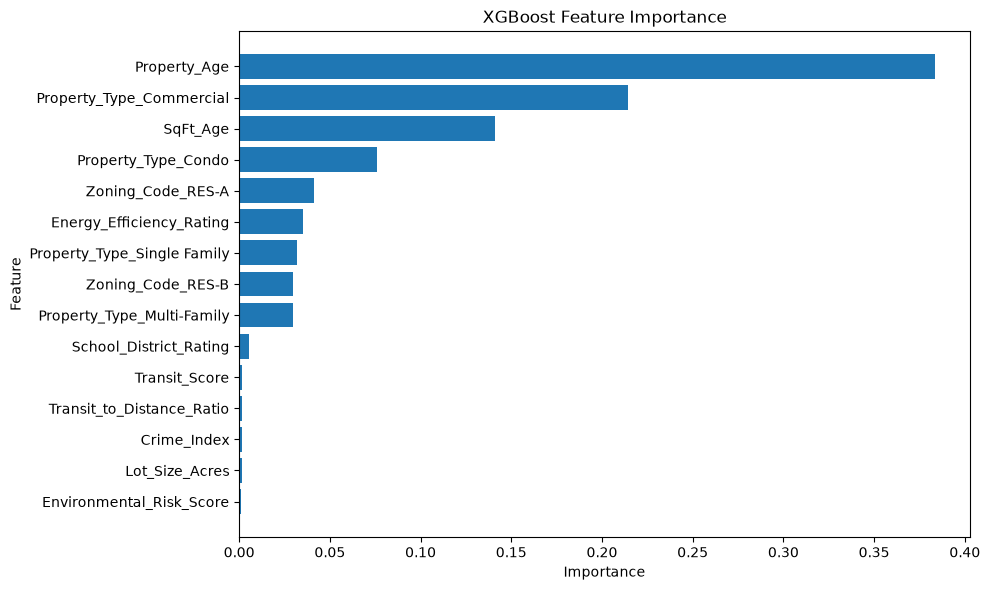

In [75]:
plt.figure(figsize=(10, 6))
plt.barh(feature_importance["Feature"].head(15)[::-1],feature_importance["Importance"].head(15)[::-1])
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("XGBoost Feature Importance")
plt.tight_layout()
plt.savefig("image/xgboost_feature_importance.png", dpi=300, bbox_inches="tight")
plt.show()

### Analyze the residuals of the XGBoost model (y_true - y_pred).

In [76]:
# Residuals
residuals = y_test_reg.values.ravel() - y_pred_xgb

print("Residual Statistics")
print("-" * 30)
print(f"Mean     : {residuals.mean():.4f}")
print(f"Median   : {np.median(residuals):.4f}")
print(f"Std Dev  : {residuals.std():.4f}")
print(f"Min      : {residuals.min():.4f}")
print(f"Max      : {residuals.max():.4f}")

Residual Statistics
------------------------------
Mean     : 751.1960
Median   : -1994.0007
Std Dev  : 357679.1806
Min      : -3227933.0059
Max      : 3749868.1832


### Plot a histogram of the residuals. Are they normally distributed? Save as residual_dist.png.

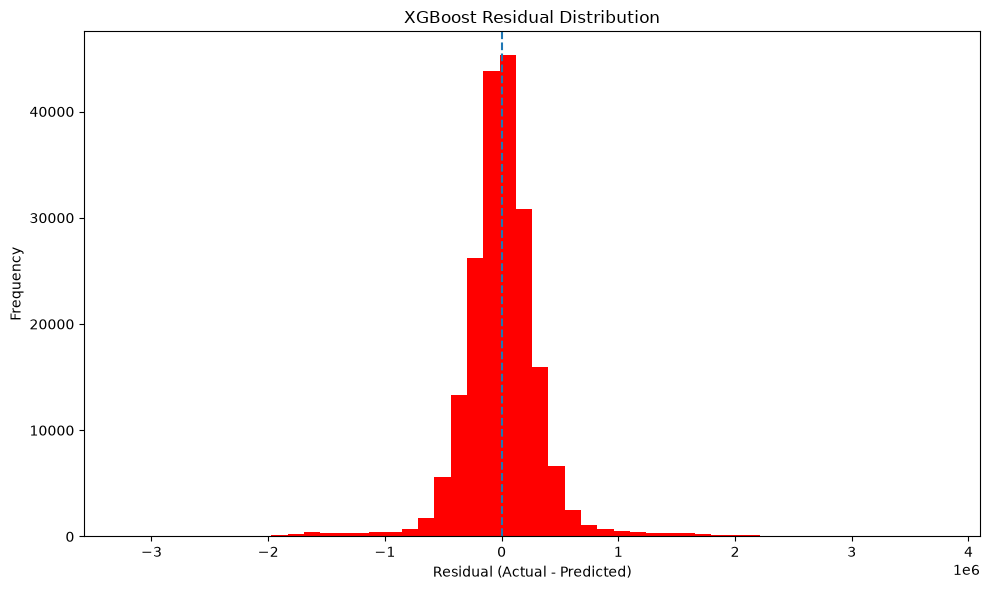

In [77]:
plt.figure(figsize=(10, 6))
plt.hist(residuals, bins=50, color='red')
plt.axvline(0, linestyle="--")
plt.xlabel("Residual (Actual - Predicted)")
plt.ylabel("Frequency")
plt.title("XGBoost Residual Distribution")
plt.tight_layout()
plt.savefig("image/residual_dist.png",dpi=300,bbox_inches="tight")
plt.show()

### Plot a scatter plot of Predicted Prices vs Actual Prices. Save as pred_vs_actual.png.

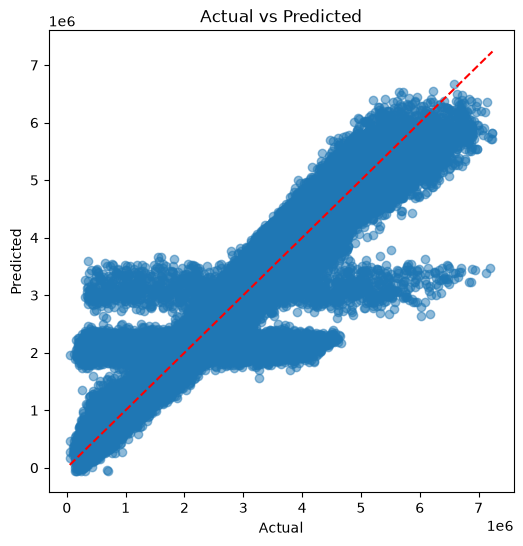

In [81]:
plt.figure(figsize=(6,6))
plt.scatter(y_test_reg, y_pred_xgb, alpha=0.5)
plt.plot(
    [y_test_reg.min(), y_test_reg.max()],
    [y_test_reg.min(), y_test_reg.max()],
    "r--"
)
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Actual vs Predicted")
plt.savefig("image/pred_vs_actual.png",dpi=300,bbox_inches="tight")
plt.show()

###  Identify heteroscedasticity: Plot Residuals vs Predicted values. Does the error variance increase for more expensive homes?

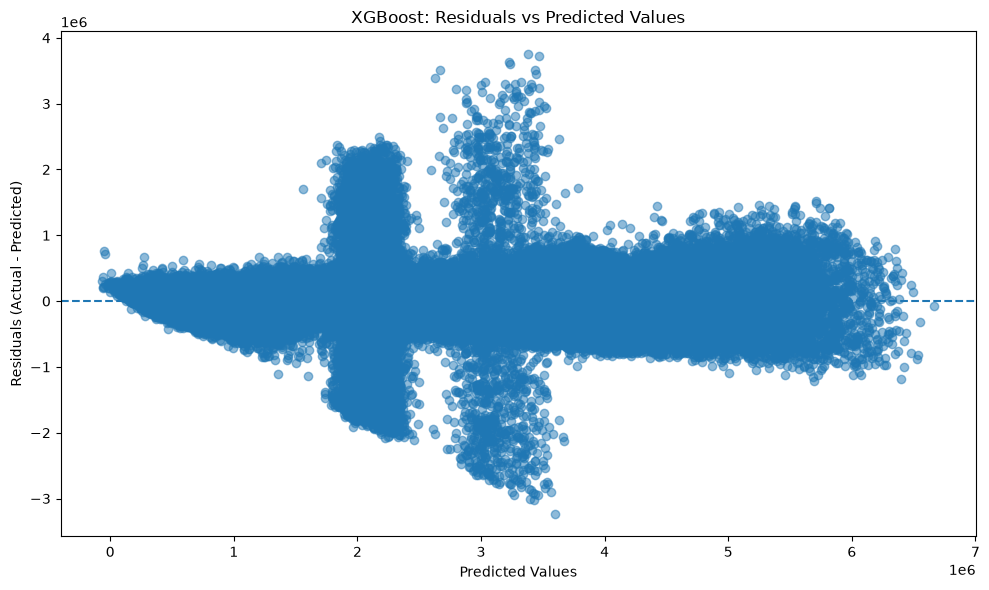

In [82]:
plt.figure(figsize=(10, 6))
plt.scatter(y_pred_xgb,residuals,alpha=0.5)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted Values")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("XGBoost: Residuals vs Predicted Values")
plt.tight_layout()
plt.savefig("image/xgboost_heteroscedasticity.png",dpi=300,bbox_inches="tight")
plt.show()

- The residual plot indicates heteroscedasticity, but the error variance does not monotonically increase with home price. Instead, the model exhibits varying error variance across different price ranges, with particularly large errors around the ₹20–₹35 lakh range.

###  the code to implement a Huber Regressor to see if it handles the high-price outliers better than XGBoost.

In [83]:
from sklearn.linear_model import HuberRegressor

In [84]:
huber_model = HuberRegressor(epsilon=1.35,max_iter=1000)

In [86]:
start_time = time.perf_counter()

huber_model.fit(X_train_reg, y_train_reg.values.ravel())

training_time = time.perf_counter() - start_time

In [88]:
y_pred_huber = huber_model.predict(X_test_reg)

In [89]:
# Evaluation
rmse_huber = np.sqrt(mean_squared_error(y_test_reg, y_pred_huber))
r2_huber = r2_score(y_test_reg,y_pred_huber)

In [90]:
print("Huber Regression")
print("-" * 30)
print(f"Training time : {training_time:.4f} seconds")
print(f"RMSE          : {rmse_huber:.4f}")
print(f"R²            : {r2_huber:.4f}")

Huber Regression
------------------------------
Training time : 17.3188 seconds
RMSE          : 1179623.1189
R²            : 0.0959


- The training time for XGBOOST is 140 sec. while HUBER REGRESSOR is around 17 Sec. So HUBER REGRESSOR is efficient as compare to XGBOOST.
- RMSE of XGBOOST is 357679.9739 while HUBER REGRESSOR  is 1179623.1189 means XGBOOST is have better accuracy than HR.
- R^2 of XGBOOST is 0.9 while HR is 0.09 means XGBOOST is have better accuracy than HR

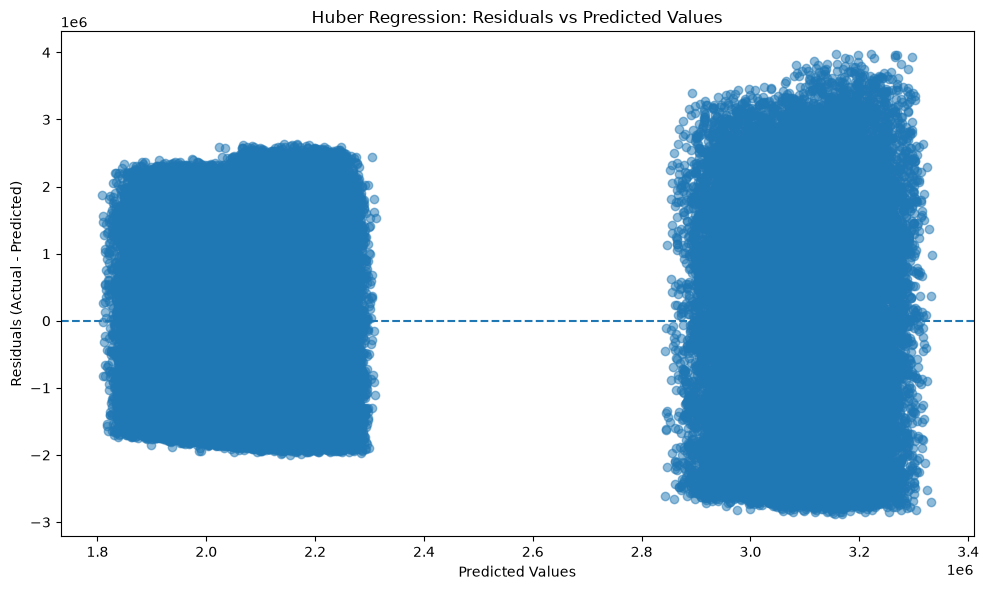

In [91]:
residuals_huber = y_test_reg.values.ravel() - y_pred_huber

plt.figure(figsize=(10, 6))
plt.scatter(y_pred_huber,residuals_huber,alpha=0.5)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted Values")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("Huber Regression: Residuals vs Predicted Values")
plt.tight_layout()
plt.savefig("image/huber_residuals_vs_predicted.png",dpi=300,bbox_inches="tight")
plt.show()

- The Huber Regressor did not outperform XGBoost in handling the high-price outliers. Although Huber Regression is designed to reduce the influence of outliers, it produced a much higher RMSE of 1,179,623.12 compared with 357,679.97 for XGBoost. The Huber residual plot also shows substantial prediction errors across the predicted-price range. Therefore, XGBoost is the better-performing model for this dataset, providing significantly more accurate predictions despite the presence of high-price outliers.

### Train the Huber Regressor and compare its Mean Absolute Error (MAE) to XGBoost.

In [93]:
mae_xgb = mean_absolute_error(y_test_reg, y_pred_xgb)
mae_huber = mean_absolute_error(y_test_reg, y_pred_huber)

print("Model Comaprision on Mean Absolute Error")
print("-" * 30)
print(f"MAE for XGBOOST          : {mae_xgb:.4f}")
print(f"MAE for HUBER REGRESSOR  : {mae_huber:.4f}")

Model Comaprision on Mean Absolute Error
------------------------------
MAE for XGBOOST          : 230285.4531
MAE for HUBER REGRESSOR  : 997709.2351


- Conclusion: XGBoost provides substantially better predictive accuracy than Huber Regression according to MAE, consistent with the earlier RMSE comparison.

### Select the best performing regression model based on test-set RMSE.

In [94]:
print("Model Comaprision on Root Mean Square Error")
print("-" * 30)
print(f"RMSE for XGBOOST          : {rmse_xgb:.4f}")
print(f"RMSE for HUBER REGRESSOR  : {rmse_huber:.4f}")

Model Comaprision on Root Mean Square Error
------------------------------
RMSE for XGBOOST          : 357679.9739
RMSE for HUBER REGRESSOR  : 1179623.1189


- Conclusion: XGBoost is clearly the better-performing model based on RMSE.

### Save the trained best model using `joblib` as best_reg_model.pkl.